In [1]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 66.2 MB/s  0:00:09m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 60.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 59.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 37.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 59.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 59.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 60.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 67.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 70.0 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 54.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 59.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36/36 [tensorflow]6 [tensorflow]]py]a-server]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 M

Coercion summary (new NaNs introduced by coercion):
  shallow_depth_s: +0 NaNs
  Deep_depth_s: +0 NaNs
  Deep_depth_t: +0 NaNs
  chlorophyll_depth: +0 NaNs
Examples of original values coerced to NaN (up to 5 examples per column):
  shallow_depth_s: []
  Deep_depth_s: []
  Deep_depth_t: []
  chlorophyll_depth: []
Dropped 2 rows with NaNs in required columns (remaining 600 rows).
Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):
     shallow_depth_s  Deep_depth_s  Deep_depth_t  chlorophyll_depth  \
170            0.100           NaN         3.463              0.724   
601            9.431        13.026           NaN              4.648   

       drop_reasons  
170  [Deep_depth_s]  
601  [Deep_depth_t]  
Saved cleaned data to 'data_cleaned.csv'
Original DataFrame shape: (602, 10)
DataFrame shape after coercion+outlier removal: (505, 10)


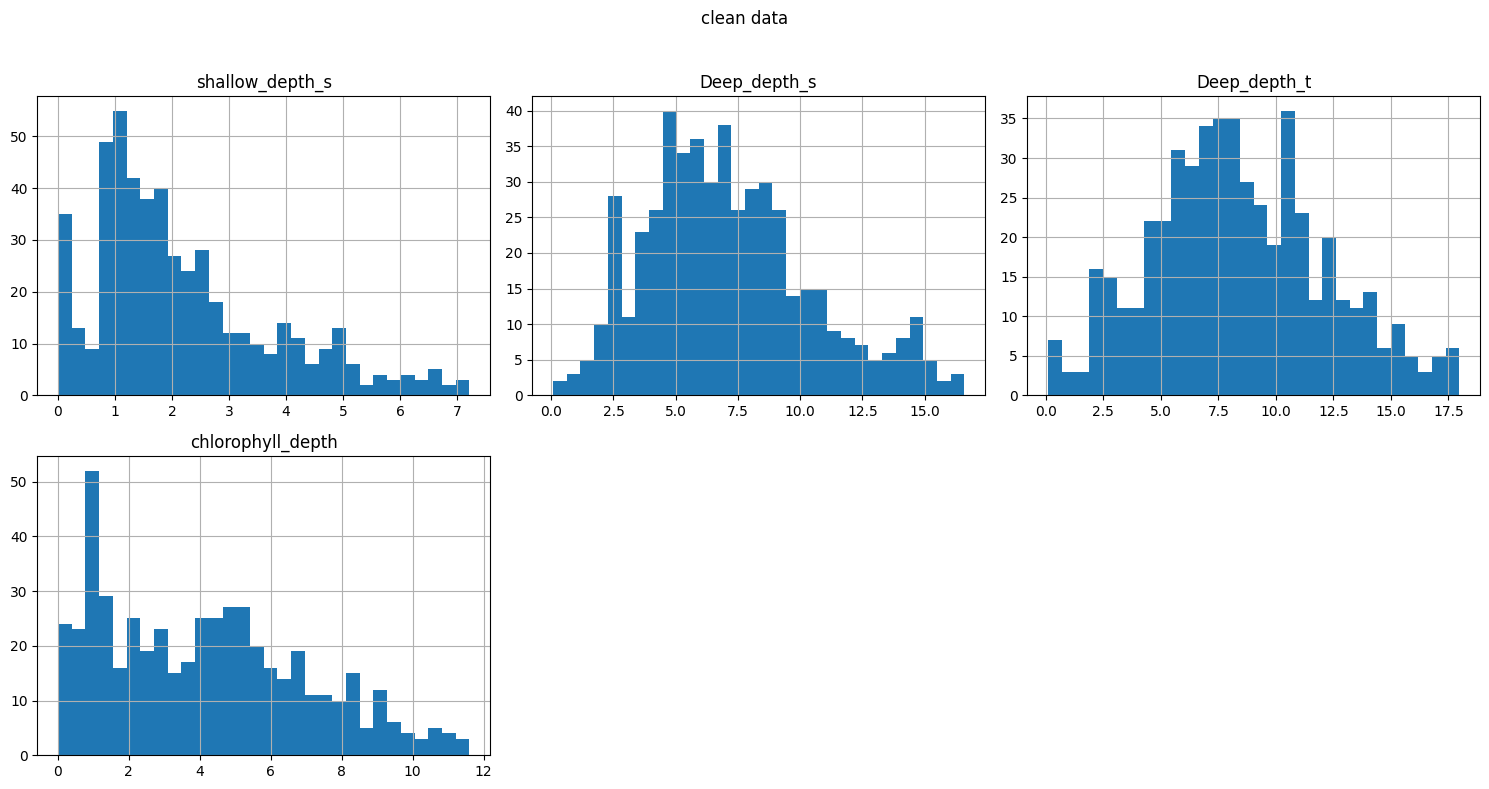

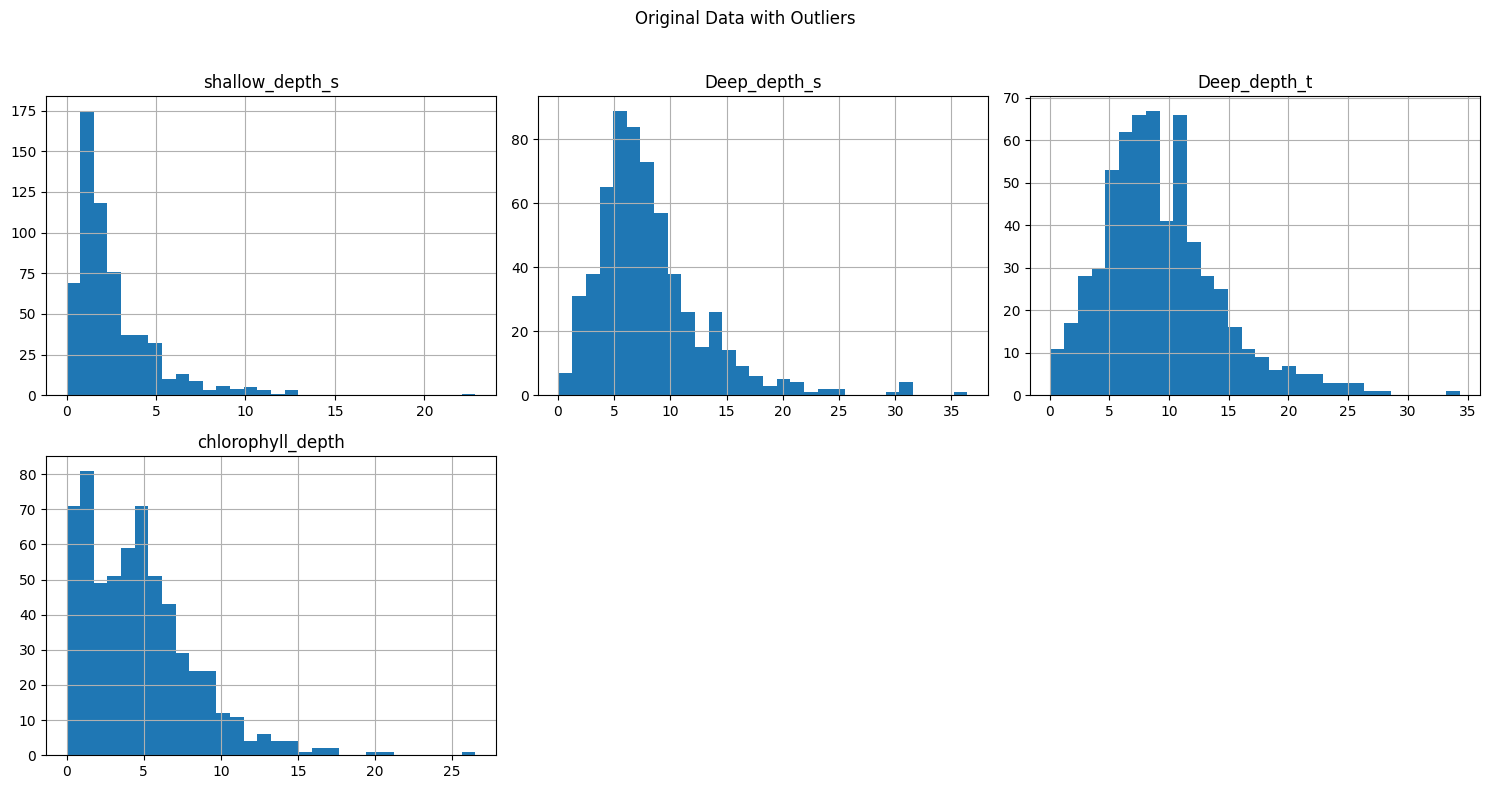

In [1]:

# 2. Load and Prepare Your Data
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Load data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

# Feature and target columns (ensure these match your CSV headers)
feature_cols = ['shallow_depth_s', 'Deep_depth_s', 'Deep_depth_t']
target_col = 'chlorophyll_depth'


def remove_outliers(df):
    """
    Removes rows containing outliers in the specified columns using the Z-score method.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]
    present_cols = [c for c in cols_to_check if c in df_cleaned.columns]
    missing_cols = [c for c in cols_to_check if c not in df_cleaned.columns]
    if missing_cols:
        print(f"Warning: Column(s) not found in the DataFrame and will be skipped: {missing_cols}")

    # Ensure we don't try to z-score constant or empty columns
    for col in present_cols:
        # coerce object columns to numeric where possible
        if df_cleaned[col].dtype == object:
            df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')
        if df_cleaned[col].dropna().nunique() <= 1:
            continue
        # compute zscore safely
        try:
            z = stats.zscore(df_cleaned[col].astype(float))
        except Exception:
            continue
        outlier_mask = np.abs(z) > 2  # adjust threshold if desired
        df_cleaned = df_cleaned[~outlier_mask]

    return df_cleaned


def coerce_and_clean_numeric(df, cols, target_col):
    """Coerce listed columns to numeric, replace infs, drop rows with NaNs, and provide diagnostics.

    Returns the cleaned DataFrame (rows kept). Also saves dropped rows to 'dropped_rows_inspection.csv'.
    """
    df2 = df.copy()
    converted = {}
    coercion_examples = {}

    for c in cols + [target_col]:
        if c in df2.columns:
            before_na = df2[c].isna().sum()
            # attempt coercion and capture examples of values that fail
            coerced = pd.to_numeric(df2[c], errors='coerce')
            coerced_mask = df2[c].notna() & coerced.isna()
            coercion_examples[c] = df2.loc[coerced_mask, c].head(5).tolist()
            df2[c] = coerced
            after_na = df2[c].isna().sum()
            converted[c] = after_na - before_na

    # Replace inf values with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    print("Coercion summary (new NaNs introduced by coercion):")
    for k, v in converted.items():
        print(f"  {k}: +{v} NaNs")

    print("Examples of original values coerced to NaN (up to 5 examples per column):")
    for k, v in coercion_examples.items():
        print(f"  {k}: {v}")

    present_cols = [c for c in cols + [target_col] if c in df2.columns]
    before = df2.shape[0]

    # identify rows that will be dropped and keep a copy for diagnostics
    dropped_rows = df2[df2[present_cols].isnull().any(axis=1)].copy() if present_cols else df2.iloc[0:0].copy()
    df2_kept = df2.dropna(subset=present_cols) if present_cols else df2.copy()
    after = df2_kept.shape[0]

    print(f"Dropped {before - after} rows with NaNs in required columns (remaining {after} rows).")

    if not dropped_rows.empty:
        # summarize drop reasons per-row
        def reasons(row):
            return [col for col in present_cols if pd.isna(row[col])]
        dropped_rows['drop_reasons'] = dropped_rows.apply(reasons, axis=1)
        # save dropped rows for inspection
        try:
            dropped_rows.to_csv('dropped_rows_inspection.csv', index=False)
            print("Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):")
        except Exception as e:
            print("Failed to save dropped_rows_inspection.csv:", e)
        display_cols = [c for c in present_cols if c in dropped_rows.columns]
        print(dropped_rows.head()[display_cols + ['drop_reasons']])

    return df2_kept


# Apply cleaning and outlier removal
if 'data' in locals():
    data_numeric = coerce_and_clean_numeric(data, feature_cols, target_col)
    data_cleaned = remove_outliers(data_numeric)
    # Save cleaned data for inspection
    try:
        data_cleaned.to_csv('data_cleaned.csv', index=False)
        print("Saved cleaned data to 'data_cleaned.csv'")
    except Exception as e:
        print("Failed to save data_cleaned.csv:", e)

    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after coercion+outlier removal:", data_cleaned.shape)
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    columns_to_plot = [c for c in feature_cols + [target_col] if c in data.columns]
    if not columns_to_plot:
        print("No columns available to plot.")
        return
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# If data_cleaned exists, plot histograms
if 'data_cleaned' in locals():
    plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
if 'data' in locals():
    plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")


Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 23.6642 - val_loss: 14.0628
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 22.4753 - val_loss: 15.8183
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 21.5499 - val_loss: 15.9590
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 21.2521 - val_loss: 15.6554
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 20.0724 - val_loss: 14.4974
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 18.9544 - val_loss: 13.6659
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 18.2006 - val_loss: 12.5648
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 17.5156 - val_loss: 12.7535
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 16.7050 - val_loss: 12.7606
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 15.3281 - val_loss: 12.0046
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 13.4397 - val_loss: 11.6262
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s

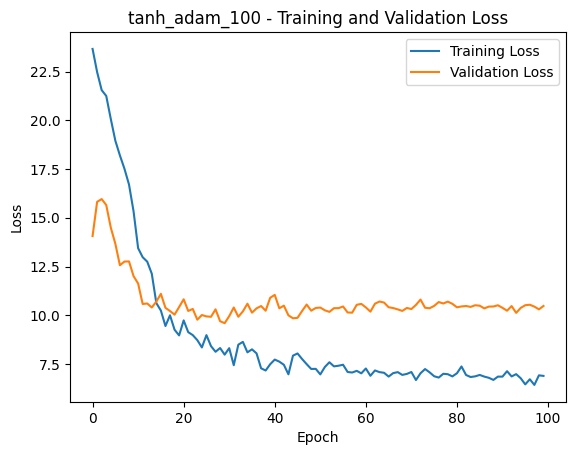

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 23.6774 - val_loss: 15.2433
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 21.9952 - val_loss: 15.0709
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 21.0397 - val_loss: 16.7256
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 19.9470 - val_loss: 14.5810
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 19.1411 - val_loss: 13.5766
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 17.6252 - val_loss: 13.1543
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 16.0841 - val_loss: 12.5712
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 15.5592 - val_loss: 11.5052
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 15.3544 - val_loss: 12.5557
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 14.5323 - val_loss: 10.9160
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.1630 - val_loss: 10.8066
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s

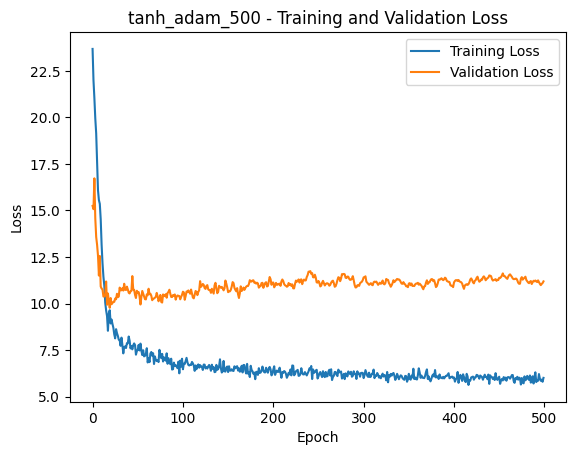

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 18.5620 - val_loss: 12.1487
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.1939 - val_loss: 10.5631
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 10.4766 - val_loss: 11.7404
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 9.1554 - val_loss: 10.6554
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.2403 - val_loss: 10.5236
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.7892 - val_loss: 10.5875
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.5911 - val_loss: 10.0990
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.8081 - val_loss: 14.5862
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.6888 - val_loss: 9.9771
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.8544 - val_loss: 10.3427
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.2716 - val_loss: 10.1741
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/ste

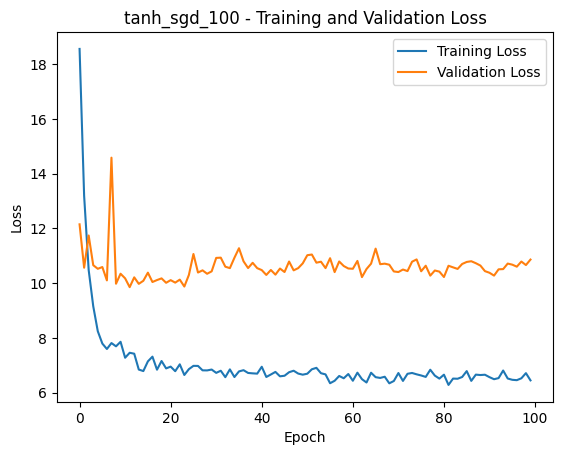

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 19.1067 - val_loss: 11.2762
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 12.8176 - val_loss: 10.6745
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.9656 - val_loss: 10.2745
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.8881 - val_loss: 10.3019
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.5887 - val_loss: 11.0303
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.7663 - val_loss: 12.8223
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.3950 - val_loss: 10.0946
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.5189 - val_loss: 11.6166
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.9682 - val_loss: 10.1473
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.3196 - val_loss: 11.4002
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.9974 - val_loss: 10.6678
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/ste

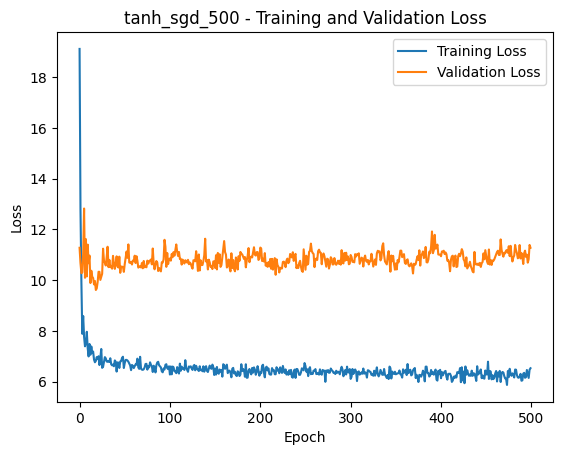

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 23.3142 - val_loss: 15.6679
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 21.3677 - val_loss: 12.7843
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 20.3187 - val_loss: 16.1781
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 19.1407 - val_loss: 13.1057
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 18.4682 - val_loss: 11.4875
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 17.4783 - val_loss: 12.2143
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 16.8037 - val_loss: 11.7780
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 15.4144 - val_loss: 11.1375
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 14.2911 - val_loss: 10.8607
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 13.3249 - val_loss: 10.7982
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 12.4275 - val_loss: 10.6702
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s

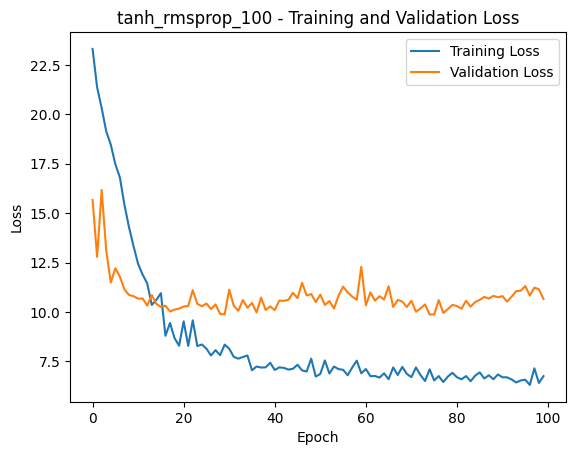

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 22.9974 - val_loss: 16.7554
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 20.9090 - val_loss: 13.6739
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 20.7352 - val_loss: 14.5433
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 19.3920 - val_loss: 13.7850
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 17.6426 - val_loss: 12.2970
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 17.5478 - val_loss: 11.3177
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 15.8857 - val_loss: 14.3193
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 15.6578 - val_loss: 11.2231
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 14.1975 - val_loss: 10.6192
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 13.1739 - val_loss: 10.6678
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 12.7650 - val_loss: 11.3741
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s

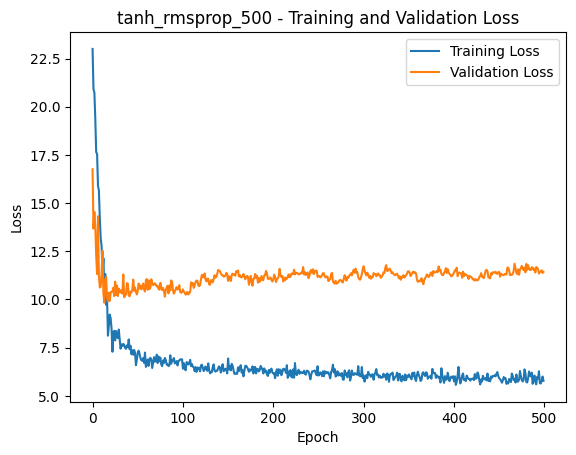

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 26.9578 - val_loss: 31.1867
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 22.8263 - val_loss: 27.1142
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 19.3670 - val_loss: 23.4138
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 16.8905 - val_loss: 20.8890
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 14.4014 - val_loss: 18.2452
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 12.8878 - val_loss: 16.0715
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 11.2374 - val_loss: 14.3143
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 9.9956 - val_loss: 13.1190
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 9.1195 - val_loss: 12.2153
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 8.7331 - val_loss: 11.5097
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 8.2628 - val_loss: 11.1191
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14m

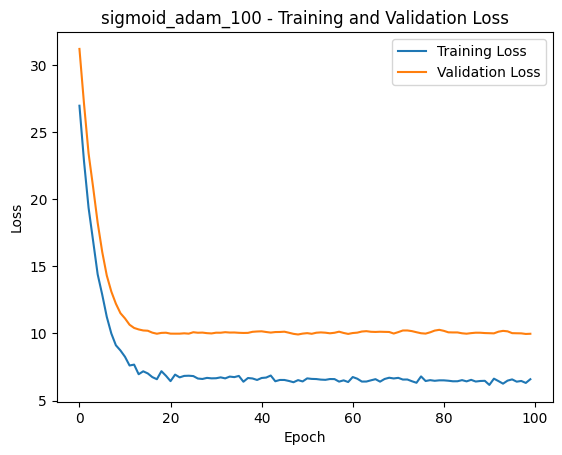

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 16.1090 - val_loss: 19.5582
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 13.4335 - val_loss: 16.7749
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 11.3202 - val_loss: 14.7624
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 10.1871 - val_loss: 13.3852
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 8.8125 - val_loss: 12.3286
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 8.3116 - val_loss: 11.5205
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 7.5205 - val_loss: 10.8850
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.0945 - val_loss: 10.4934
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 6.7441 - val_loss: 10.3092
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 6.8832 - val_loss: 10.1276
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.9325 - val_loss: 10.1295
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/s

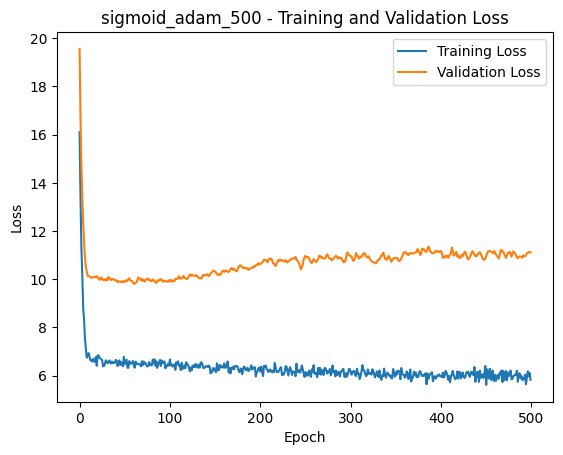

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 10.1062 - val_loss: 10.2083
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.8654 - val_loss: 11.1365
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 6.8347 - val_loss: 11.5411
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 7.2637 - val_loss: 10.1961
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 6.7994 - val_loss: 12.6885
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.2328 - val_loss: 10.4043
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.7889 - val_loss: 11.6101
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.8995 - val_loss: 13.0811
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.2669 - val_loss: 13.5400
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 7.6990 - val_loss: 11.5581
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.8168 - val_loss: 10.1271
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

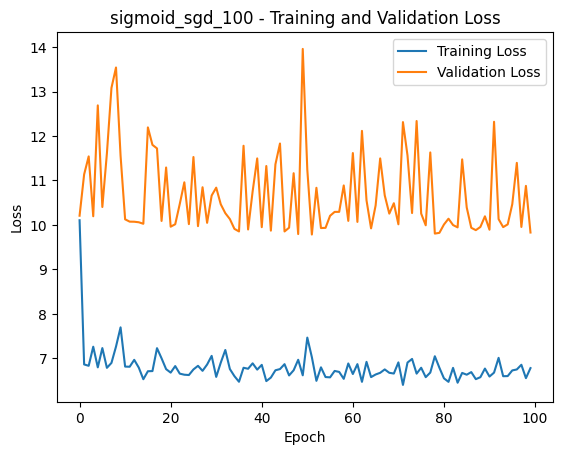

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 9.8471 - val_loss: 12.0439
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.3667 - val_loss: 12.8375
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.1521 - val_loss: 10.2116
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.7561 - val_loss: 11.7603
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.8878 - val_loss: 10.7990
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.8298 - val_loss: 14.1997
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.3912 - val_loss: 15.0238
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.3631 - val_loss: 10.5170
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 6.7856 - val_loss: 10.1291
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.7318 - val_loss: 10.1152
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 6.7768 - val_loss: 12.0230
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step 

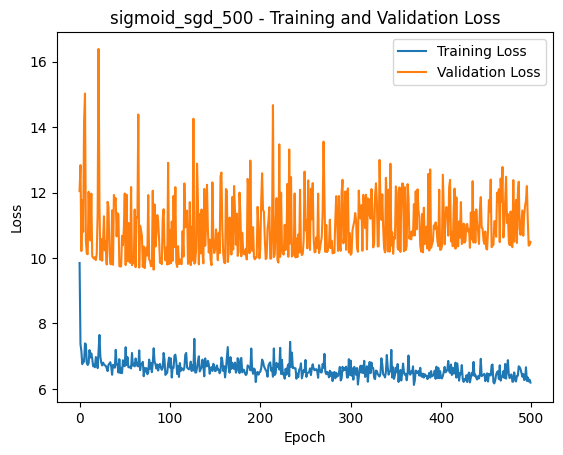

Epoch 1/100


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 24.3315 - val_loss: 24.8237
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 20.4017 - val_loss: 21.4337
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 17.2426 - val_loss: 18.6093
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 14.8563 - val_loss: 16.4155
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 12.1800 - val_loss: 14.2413
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 10.7941 - val_loss: 12.6097
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 9.4016 - val_loss: 11.6681
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.2883 - val_loss: 10.8955
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.7618 - val_loss: 10.3593
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.1879 - val_loss: 10.2511
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.2459 - val_loss: 10.0692
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms

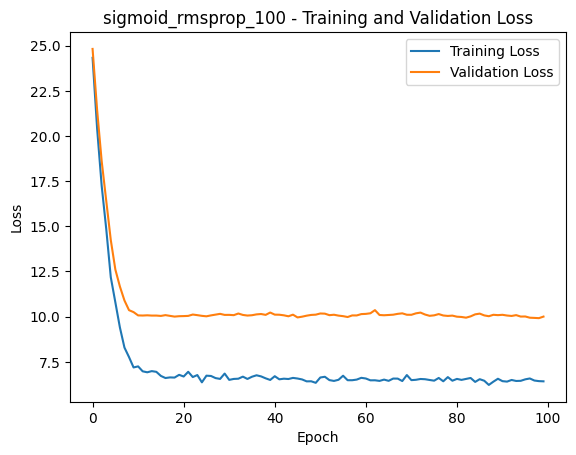

Epoch 1/500


/home/jpoulet/src/Chlorocline-Predictor/.venv/lib/python3.12/site-packages/keras/src/layers/regularization/gaussian_noise.py:29: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 20.8654 - val_loss: 22.9386
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 16.5966 - val_loss: 19.7574
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 14.3315 - val_loss: 17.0433
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 12.0335 - val_loss: 15.2303
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 10.6960 - val_loss: 13.6213
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 9.3591 - val_loss: 12.4338
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.1707 - val_loss: 11.3882
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.5636 - val_loss: 10.9768
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.3690 - val_loss: 10.6616
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.0294 - val_loss: 10.4487
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.9286 - val_loss: 10.1704
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/

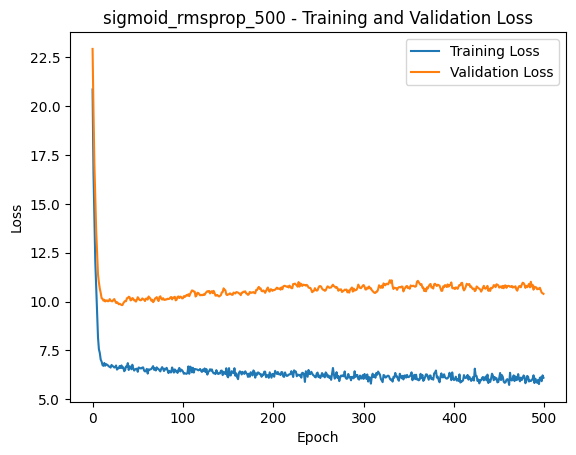

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split  # <-- Add this import
from tensorflow.keras.models import Sequential  # <-- Add this import
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, GaussianNoise  # <-- Updated import

# Assuming you have run the data preparation code and have `data_cleaned`
# Use the cleaned DataFrame for splitting so the model doesn't get NaNs/infs
train_df, temp_df = train_test_split(data_cleaned, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]

# Quick sanity checks: ensure there are no NaNs or infs in inputs/targets
def has_invalid(x):
    return np.isnan(x).any() or np.isinf(x).any()

for name, arr in [('x_train', x_train.values), ('y_train', y_train.values), ('x_val', x_val.values), ('y_val', y_val.values), ('x_test', x_test.values), ('y_test', y_test.values)]:
    if has_invalid(arr):
        raise ValueError(f"Invalid values found in {name} (NaN or Inf). Check data_cleaned and preprocessing.")

# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [100, 500]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            # Use the provided architecture, parameterized by the current activation
            model = Sequential([
                GaussianNoise(0.1, input_shape=(x_train.shape[1],)),
                Dense(256, activation=activation),
                BatchNormalization(),
                Dropout(0.5),
                Dense(128, activation=activation),
                BatchNormalization(),
                Dropout(0.5),
                Dense(64, activation=activation),
                Dense(1)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [9]:
import numpy as np

if not models:
    print('No models found in `models`. Did the training cell run?')
else:
    def _safe_mse(item):
        """Return a numeric MSE for sorting or +inf when unavailable/NaN."""
        v = item[1]
        try:
            # expect v like (model, mse) or (model, mse, history)
            m = v[1]
            m = float(m)
        except Exception:
            m = float('nan')
        return m if not np.isnan(m) else float('inf')

    sorted_models = sorted(models.items(), key=_safe_mse)
    print("Models sorted by Test MSE (lowest to highest):")
    for name, val in sorted_models:
        try:
            mse_val = val[1]
            mse_str = f"{float(mse_val):.6g}"
        except Exception:
            mse_str = 'N/A'
        print(f"{name}: Test MSE = {mse_str}")

Models sorted by Test MSE (lowest to highest):
tanh_rmsprop_500: Test MSE = 6.25772
sigmoid_sgd_100: Test MSE = 6.49271
sigmoid_adam_100: Test MSE = 6.526
tanh_adam_100: Test MSE = 6.5423
sigmoid_adam_500: Test MSE = 6.57176
sigmoid_rmsprop_100: Test MSE = 6.58586
sigmoid_sgd_500: Test MSE = 6.62898
tanh_adam_500: Test MSE = 6.65399
tanh_rmsprop_100: Test MSE = 6.85208
tanh_sgd_100: Test MSE = 6.96295
sigmoid_rmsprop_500: Test MSE = 6.98296
tanh_sgd_500: Test MSE = 7.33856


Model: tanh_adam_100, Test MSE: 6.935699462890625
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


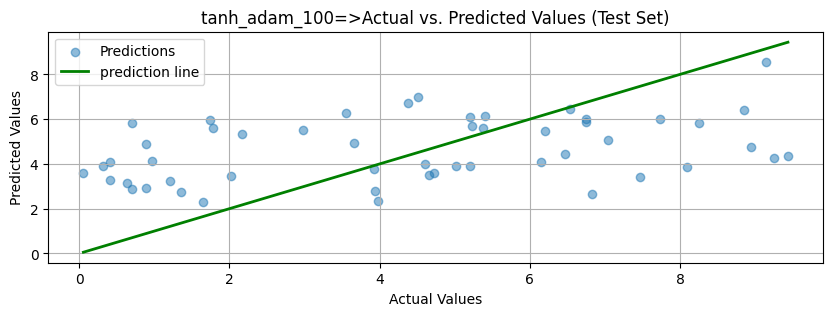

Model: tanh_adam_500, Test MSE: 7.444221019744873
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


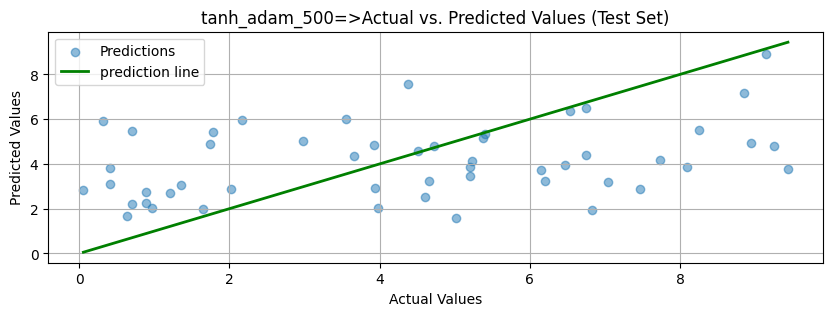

Model: tanh_sgd_100, Test MSE: 6.224243640899658
1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7c465c3b89a0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


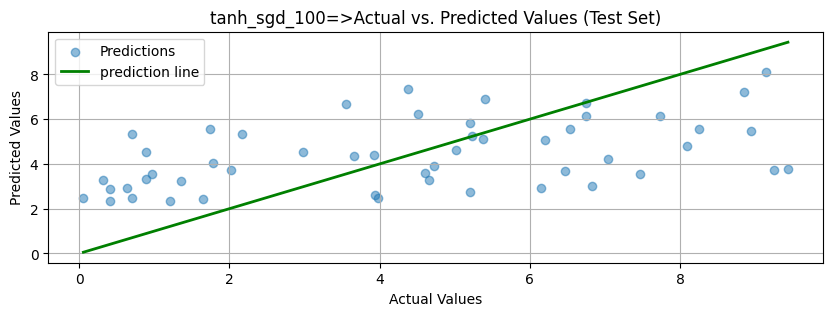

Model: tanh_sgd_500, Test MSE: 7.134983062744141
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


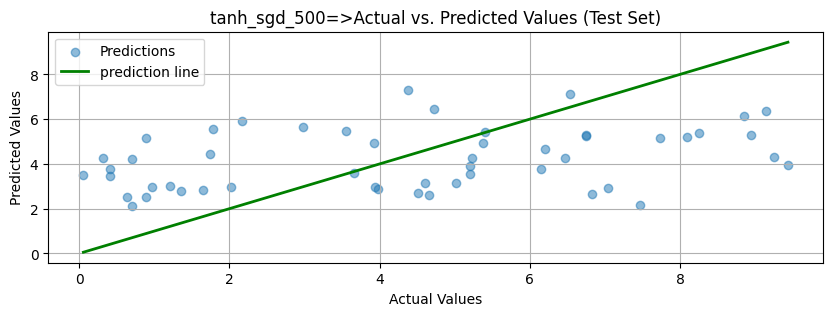

Model: tanh_rmsprop_100, Test MSE: 6.491157054901123
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


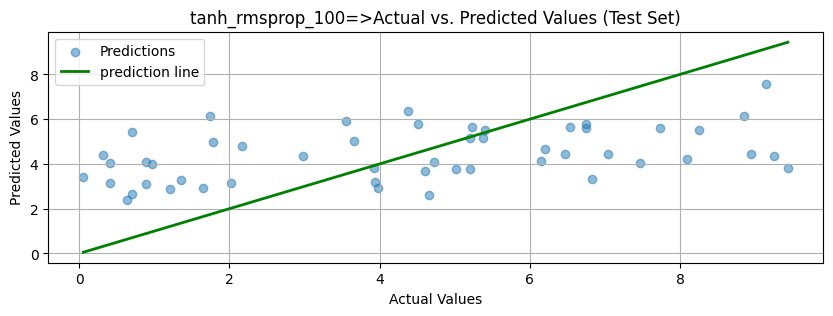

Model: tanh_rmsprop_500, Test MSE: 7.550005912780762
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


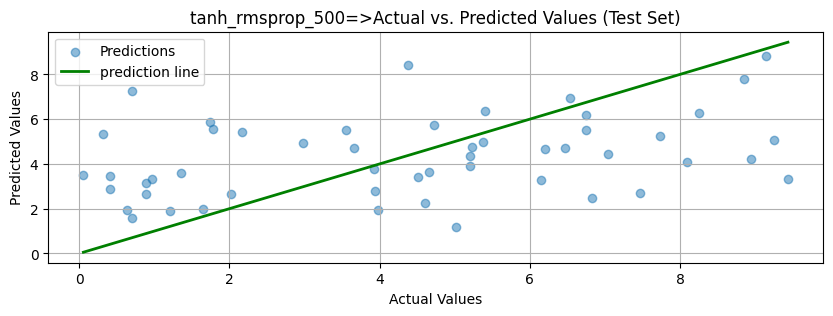

Model: sigmoid_adam_100, Test MSE: 6.429197788238525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


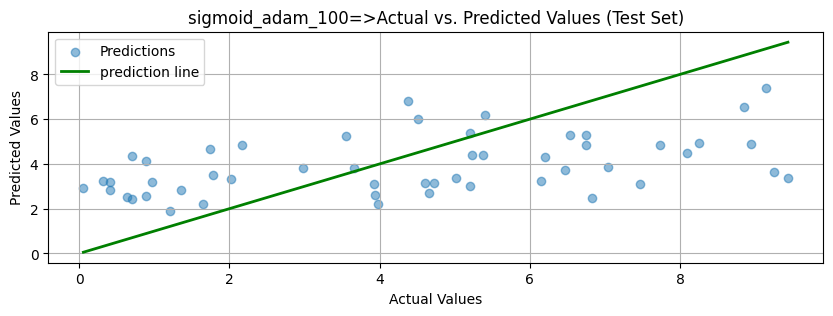

Model: sigmoid_adam_500, Test MSE: 7.158296585083008
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


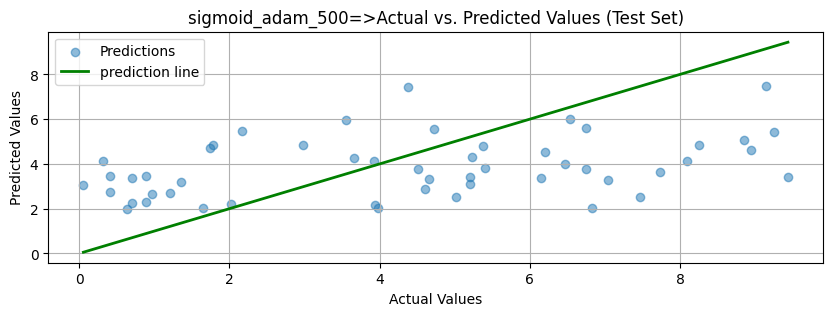

Model: sigmoid_sgd_100, Test MSE: 7.610015392303467
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


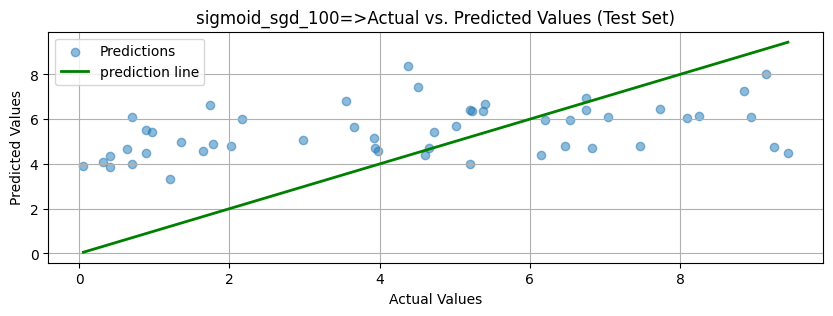

Model: sigmoid_sgd_500, Test MSE: 6.40908145904541
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


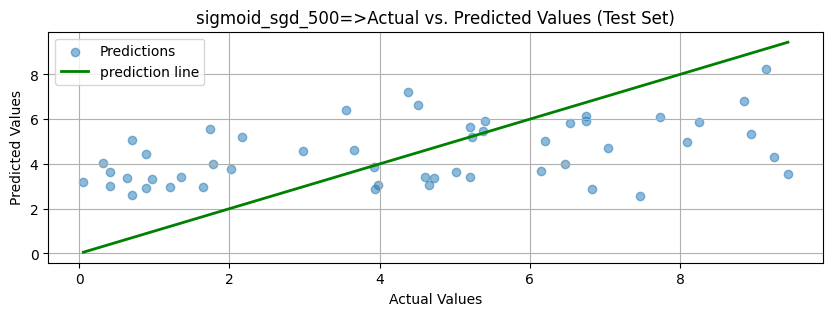

Model: sigmoid_rmsprop_100, Test MSE: 6.219410419464111
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


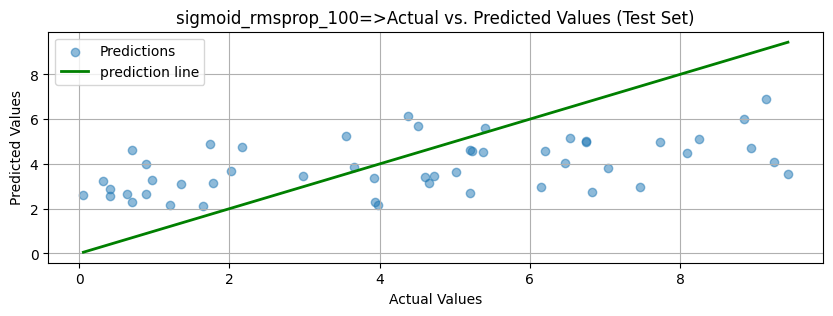

Model: sigmoid_rmsprop_500, Test MSE: 6.873189449310303
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


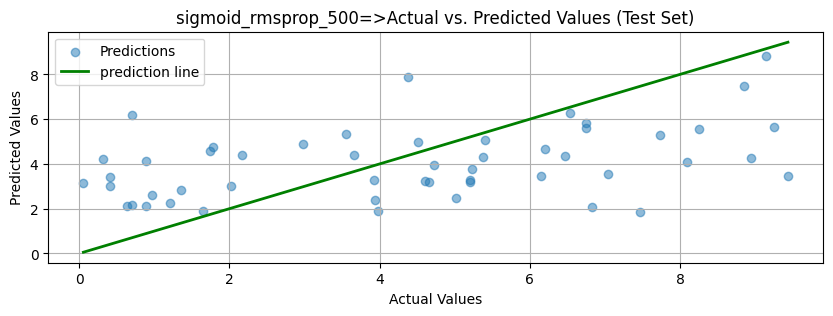

In [5]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")